In [1]:
import sys
import os
import numpy as np
import matplotlib.pyplot as plt
import librosa
import IPython.display as ipd

# Point to single_stroke_synthesis/src
sys.path.append(os.path.abspath(os.path.join('..', 'src')))
from modal2 import ModalSynthesizer
from optimize import optimize_modes
from utils import plot_acoustic_comparison
from extract_modes import extract_exact_modes, extract_exciter_params, extract_stroke_constraints, extract_frequency_damping

sr = 44100
synth = ModalSynthesizer(sr=sr)
print("Modal Synthesis Engine Loaded.")

Modal Synthesis Engine Loaded.


/home/dibahadie/Projects/Research/Tonbak-Sound-Analysis-and-Synthesis/single_stroke_synthesis/src/utils.py:71: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


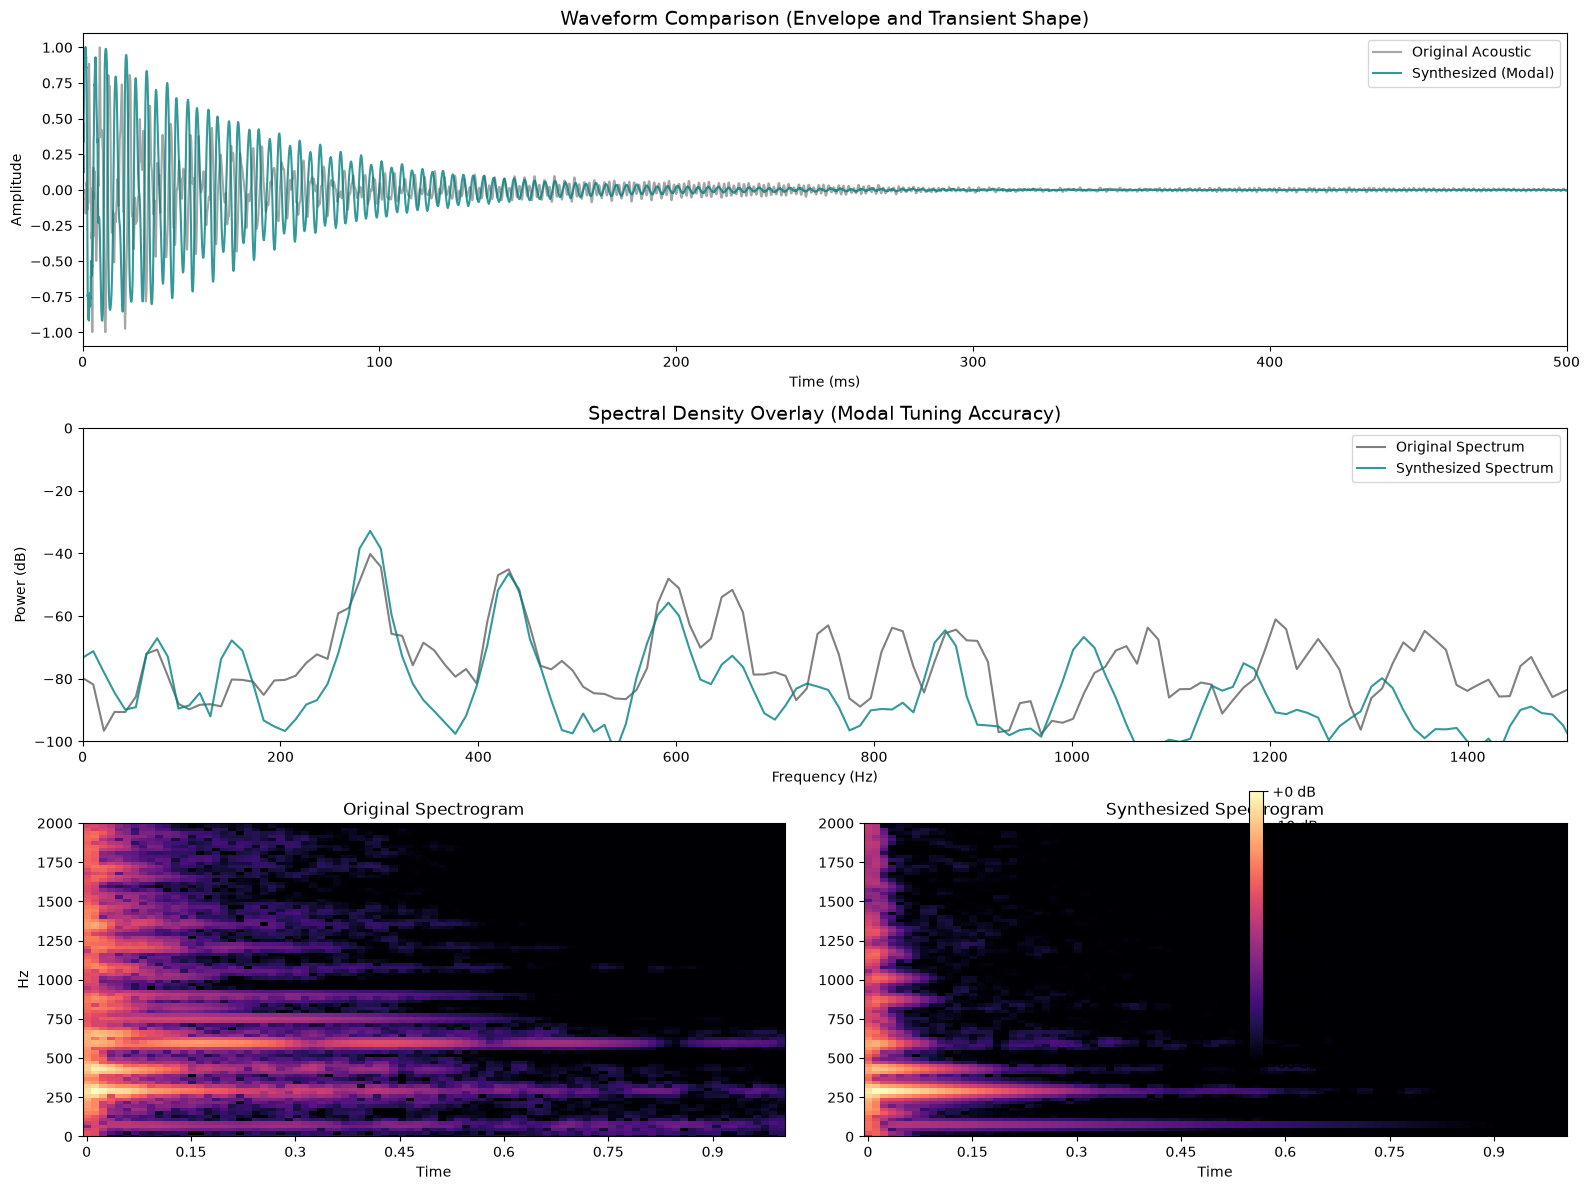

In [7]:
import copy

stroke = 'hit_mid'
original_audio_path = f"../../single_stroke_analysis/data/raw/{stroke}/GIO_MEE_tombak_{stroke}.wav"
original_audio, sr = librosa.load(original_audio_path, sr=44100)

exact_modes = extract_exact_modes(original_audio)
exciter_params = extract_exciter_params(original_audio)
stroke_constraints = extract_stroke_constraints(original_audio, sr=44100)
frequency_damping = extract_frequency_damping(original_audio)

stroke_constraints.update(frequency_damping)

# 2. A subtle, natural friction level (not 0.02, not 0.001)
stroke_constraints['body_noise_amp'] = 0.015
stroke_constraints['body_noise_decay'] = 4.0

stroke_constraints['click_gain'] = 5.0
stroke_constraints['exciter_drive'] = 1.5
stroke_constraints['dry_mix_ratio'] = 0.1
stroke_constraints['damping_pivot_hz'] = 400.0
stroke_constraints['damping_exponent'] = 1.2
stroke_constraints['max_q_clamp'] = 45.0

# 1. Identify the fundamental (lowest) frequency in your extracted modes
fundamental_mode = min(exact_modes, key=lambda x: x['freq'])

# 2. Create the Ghost Mode (Subtle, long-ringing wooden tail)
ghost_mode = {
    'freq': fundamental_mode['freq'],
    'amp': fundamental_mode['amp'] * 0.1,  # Only 3% of the original volume
    'q': 250.0,                             # Massive Q to force a long tail
    'decay_mult': 1.0
}

# 3. Append the ghost mode to your extraction
modes_with_tail = exact_modes + [ghost_mode]

# 4. Open the clamp ceiling specifically for the bass frequencies
stroke_constraints['bass_sustain_multiplier'] = 1.0 

# Synthesize with a healthy, loud exciter boost
test_audio = synth.synthesize(
    modes=exact_modes,
    constraints=stroke_constraints,
    duration=1.0,
    attack_ms=exciter_params['attack_ms'],
    decay_ms=exciter_params['decay_ms'],
    noise_fc=exciter_params['noise_fc'],
    noise_q=exciter_params['noise_q']
)

# Play it and plot it
import IPython.display as ipd
display(ipd.Audio(test_audio, rate=sr))
display(ipd.Audio(original_audio, rate=sr))
plot_acoustic_comparison(original_audio, test_audio)